# LP-III Practical B-6
### Problem Statement:
Implement K-Means clustering/ hierarchical clustering on `sales_data_sample.csv` dataset. Determine the number of clusters using the elbow method.

* **Dataset link:** https://www.kaggle.com/datasets/kyanyoga/sample-sales-data
* **Student:** GEET VILAS JAMDAL
* **Roll No:** BEA56


In [2]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.metrics import calinski_harabasz_score
from sklearn.metrics import davies_bouldin_score


# The error UnicodeDecodeError means that the CSV file sales_data_sample.csv is not encoded in utf-8,
# which is the default encoding pandas tries to use. Fix this by specifying encoding='latin1'.
df = pd.read_csv('sales_data_sample.csv', encoding='latin1')
df.head()


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


In [4]:
df.describe()


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,QTR_ID,MONTH_ID,YEAR_ID,MSRP
count,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.000000,2823.00000,2823.000000
mean,10258.725115,35.092809,83.658544,6.466171,3553.889072,2.717676,7.092455,2003.81509,100.715551
std,92.085478,9.741443,20.174277,4.225841,1841.865106,1.203878,3.656633,0.69967,40.187912
min,10100.000000,6.000000,26.880000,1.000000,482.130000,1.000000,1.000000,2003.00000,33.000000
25%,10180.000000,27.000000,68.860000,3.000000,2203.430000,2.000000,4.000000,2003.00000,68.000000
50%,10262.000000,35.000000,95.700000,6.000000,3184.800000,3.000000,8.000000,2004.00000,99.000000
75%,10333.500000,43.000000,100.000000,9.000000,4508.000000,4.000000,11.000000,2004.00000,124.000000
max,10425.000000,97.000000,100.000000,18.000000,14082.800000,4.000000,12.000000,2005.00000,214.000000


In [5]:
# Select Numerical Features
features = ['QUANTITYORDERED', 'SALES']
X = df[features]

# Group orders based on order quantity and total sales value.
# For example, clusters may roughly represent:
# Cluster 1: Low quantity + Low sales
# Cluster 2: Medium quantity + Medium sales
# Cluster 3: High quantity + High sales
X.isnull().sum()


,0
QUANTITYORDERED,0
SALES,0


In [6]:
# Feature Scaling
# Since clustering depends on distance, scaling is necessary.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


In [7]:
wcss = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42)
    model.fit(X_scaled)
    wcss.append(model.inertia_)
print(wcss)


[5646.000000000008, 2742.367116370699, 1836.7746707518625, 1516.9908506307474, 1232.2341105277574, 1020.6478553700855, 890.3466316367345, 834.1105082118644, 707.6795487819721, 668.3284302674709]


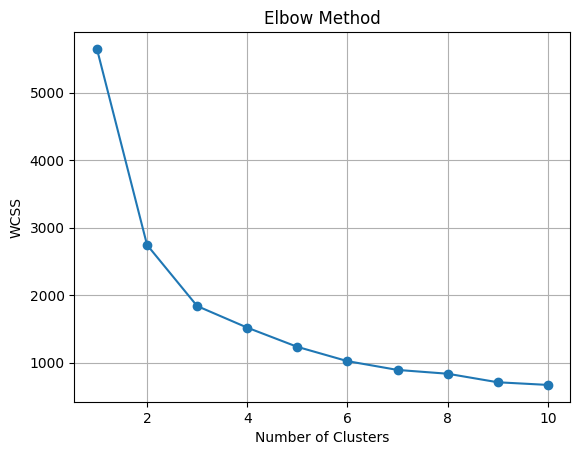

In [8]:
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid(True)
plt.show()


In [9]:
# Using the elbow method, the optimal number of clusters is determined to be 3.
# Therefore, the sales orders are divided into three clusters based on QUANTITYORDERED and SALES
kmeans = KMeans(n_clusters=3, random_state=42)
kmeans_labels = kmeans.fit_predict(X_scaled)
df['KMeans_Cluster'] = kmeans_labels
print(df[['KMeans_Cluster']].head())


   KMeans_Cluster
0               0
1               1
2               1
3               1
4               2


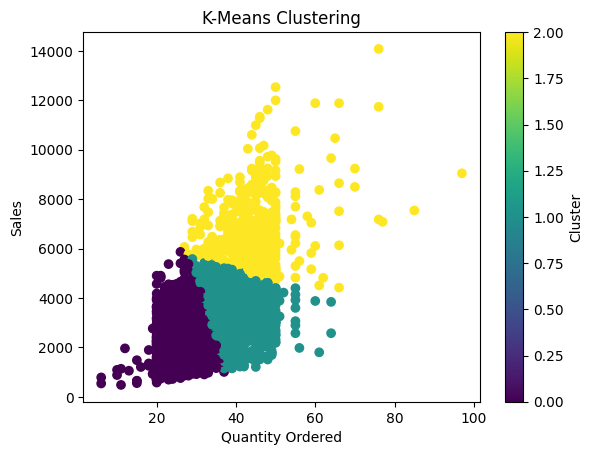

In [10]:
plt.scatter(df['QUANTITYORDERED'], df['SALES'], c=kmeans_labels, cmap='viridis')
plt.xlabel('Quantity Ordered')
plt.ylabel('Sales')
plt.title('K-Means Clustering')
plt.colorbar(label='Cluster')
plt.show()


In [11]:
# Hierarchical Clustering
hc = AgglomerativeClustering(n_clusters=3)
hc_labels = hc.fit_predict(X_scaled)
df['Hierarchical_Cluster'] = hc_labels
print(df[['Hierarchical_Cluster']].head())


   Hierarchical_Cluster
0                     0
1                     0
2                     0
3                     2
4                     1


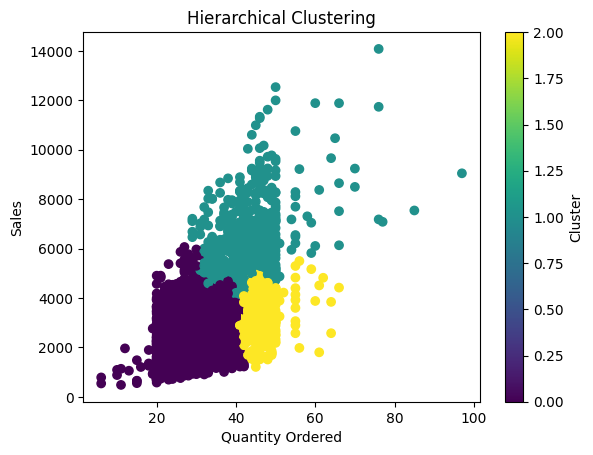

In [12]:
plt.scatter(df['QUANTITYORDERED'], df['SALES'], c=hc_labels, cmap='viridis')
plt.xlabel('Quantity Ordered')
plt.ylabel('Sales')
plt.title('Hierarchical Clustering')
plt.colorbar(label='Cluster')
plt.show()


In [13]:
print("\nK-Means Evaluation")
print("Silhouette Score :", silhouette_score(X_scaled, kmeans_labels))
print("Calinski-Harabasz Score :", calinski_harabasz_score(X_scaled, kmeans_labels))
print("Davies-Bouldin Index :", davies_bouldin_score(X_scaled, kmeans_labels))

print("\nHierarchical Clustering Evaluation")
print("Silhouette Score :", silhouette_score(X_scaled, hc_labels))
print("Calinski-Harabasz Score :", calinski_harabasz_score(X_scaled, hc_labels))
print("Davies-Bouldin Index :", davies_bouldin_score(X_scaled, hc_labels))



K-Means Evaluation
Silhouette Score : 0.4124139914988059
Calinski-Harabasz Score : 2924.1516663779503
Davies-Bouldin Index : 0.8719925728186187

Hierarchical Clustering Evaluation
Silhouette Score : 0.3830988938058836
Calinski-Harabasz Score : 2306.8161964376663
Davies-Bouldin Index : 0.8144832613529062
